<a href="https://colab.research.google.com/github/oleg61/DataScient/blob/Learn_AI/%D0%92%D0%BE%D1%80%D0%BE%D0%BF%D0%B0%D0%B5%D0%B2_%D0%9E%D0%A1_%D0%9E%D1%81%D0%BD%D0%BE%D0%B2%D1%8B_%D0%BD%D0%B5%D0%B9%D1%80%D0%BE%D0%BD%D0%BD%D1%8B%D1%85_%D1%81%D0%B5%D1%82%D0%B5%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание: основы нейронных сетей — один нейрон

**Автор:** Воропаев О.С.

**Цель задания:** научиться обучать простейшую нейросетевую модель, практически эквивалентную алгоритму линейной регрессии, методом градиентного спуска в PyTorch.

**Датасет:** California Housing Prices. Почему не Boston: датасет Boston House Prices удалён из scikit-learn начиная с версии 1.2 (проблемная с точки зрения этики переменная `B`), а скачивание с Kaggle требует API-токена. Датасет California Housing (`sklearn.datasets.fetch_california_housing`) доступен без токена и по смыслу — тот же тип задачи: по признакам района предсказать медианную стоимость дома (в сотнях тысяч долларов).

**План по инструкции к заданию:**

1. Загрузить и подготовить данные.
2. Разделить данные на train и test.
3. Создать модель (объект класса) — используем `torch.nn.Sequential`.
4. Обучить модель на train данных градиентным спуском.
5. Проверить качество модели на тестовых данных.


In [ ]:
%matplotlib inline

## 1. Загрузка и подготовка данных


In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('device:', device)

device: cpu


In [ ]:
data = fetch_california_housing()
X, y = data.data, data.target

df = pd.DataFrame(X, columns=data.feature_names)
df[data.target_names[0]] = y
print('Объектов:', X.shape[0], '| признаков:', X.shape[1])
df.head()

Объектов: 20640 | признаков: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Признаки измеряются в совершенно разных масштабах (от долей `AveOccup` до тысяч `Population`), а целевая переменная — в сотнях тысяч долларов. Для градиентного спуска это важно: без нормализации путь к оптимуму «извитой» (эллипсоидные линии уровня вытянуты), и сходимость медленная или вовсе нестабильная. Поэтому стандартизуем признаки и цель по статистикам train-выборки (скейлеры обучаем только на train, чтобы не «подглядывать» в тест).

Отметим также: в данных есть выбросы (например, `AveRooms` до 141 при медиане ~5) — линейной модели они будут мешать, но для этого учебного задания оставляем всё как есть.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)
print('train:', X_train.shape, '| test:', X_test.shape)

scaler_X = StandardScaler().fit(X_train)
scaler_y = StandardScaler().fit(y_train.reshape(-1, 1))

X_train_t = torch.tensor(scaler_X.transform(X_train), dtype=torch.float32, device=device)
X_test_t = torch.tensor(scaler_X.transform(X_test), dtype=torch.float32, device=device)
y_train_t = torch.tensor(scaler_y.transform(y_train.reshape(-1, 1)), dtype=torch.float32, device=device)
y_test_t = torch.tensor(scaler_y.transform(y_test.reshape(-1, 1)), dtype=torch.float32, device=device)

print('тензоры:', X_train_t.shape, y_train_t.shape)

train: (16512, 8) | test: (4128, 8)
тензоры: torch.Size([16512, 8]) torch.Size([16512, 1])


## 2. Модель: нейронная сеть из одного нейрона

Один нейрон — это `nn.Linear(8, 1)`: 8 входов (по числу признаков), веса $w$, смещение $b$, выход $\hat{y} = w^T x + b$. Функция активации не подключена, поэтому модель вырождается в обычную **линейную регрессию** — ровно то, что требуется в цели задания. Собираем модель через `nn.Sequential`, как предложено в инструкции.


In [ ]:
model = nn.Sequential(nn.Linear(X.shape[1], 1)).to(device)
print(model)
print('Число параметров:', sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=8, out_features=1, bias=True)
)
Число параметров: 9


## 3. Обучение градиентным спуском

Обучаем **полным батчем**: весь train-набор — один тензоры `(16512, 8)`, он легко помещается в память. Одна эпоха = один шаг градиентного спуска по среднеквадратичной ошибке (MSE).

Шаг обучения — критичный гиперпараметр: при `lr = 0.5` спуск расходится (лосс растёт с 1.01 до десятков тысяч), потому что коррелированные признаки (например, `AveRooms`/`AveBedrms`) делают линии уровня функции потерь вытянутыми и большой шаг «перескакивает» оптимум. При `lr = 0.1` процесс устойчиво сходится.


In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

n_epochs = 1000
loss_history = []

start = time.time()
for epoch in range(1, n_epochs + 1):
    optimizer.zero_grad()          # обнуляем градиенты
    predictions = model(X_train_t) # прямой проход
    loss = criterion(predictions, y_train_t)
    loss.backward()                # обратный проход: считаем градиенты
    optimizer.step()               # шаг градиентного спуска: w -= lr * grad
    loss_history.append(loss.item())
    if epoch == 1 or epoch % 100 == 0:
        print('epoch %4d | train MSE (нормир.) = %.5f' % (epoch, loss.item()))
train_time = time.time() - start
print('Время обучения: %.1f с' % train_time)

epoch    1 | train MSE (нормир.) = 1.01289
epoch  100 | train MSE (нормир.) = 0.39313


epoch  200 | train MSE (нормир.) = 0.38805
epoch  300 | train MSE (нормир.) = 0.38753


epoch  400 | train MSE (нормир.) = 0.38746
epoch  500 | train MSE (нормир.) = 0.38745


epoch  600 | train MSE (нормир.) = 0.38745
epoch  700 | train MSE (нормир.) = 0.38745


epoch  800 | train MSE (нормир.) = 0.38745
epoch  900 | train MSE (нормир.) = 0.38745


epoch 1000 | train MSE (нормир.) = 0.38745
Время обучения: 1.4 с


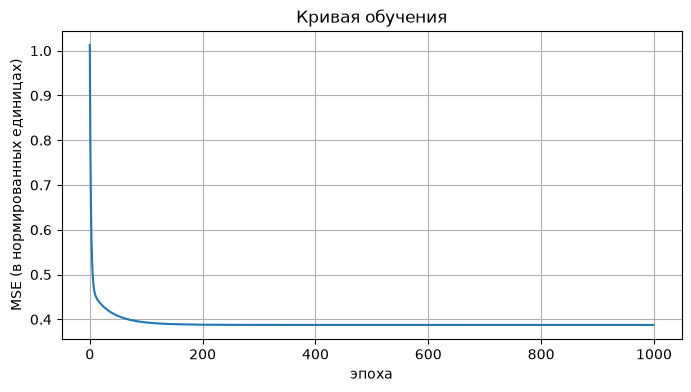

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title('Кривая обучения')
plt.xlabel('эпоха')
plt.ylabel('MSE (в нормированных единицах)')
plt.grid(True)
plt.show()

## 4. Качество модели на тестовых данных

Прогнозы переводим обратно из нормированных единиц в исходные (сотни тысяч долларов) и считаем на **test**:

* **RMSE** — корень из среднеквадратичной ошибки;
* **MAE** — средняя абсолютная ошибка;
* **$R^2$** — доля объяснённой дисперсии (1 — идеально, 0 — не лучше среднего).

Для сравнения — два ориентира: «глупый» бейзлайн (всегда предсказывать среднее по train) и аналитическая линейная регрессия `sklearn.LinearRegression` (решение методом наименьших квадратов в явной формуле, без градиентного спуска).


In [ ]:
model.eval()
with torch.no_grad():
    pred_test_scaled = model(X_test_t).cpu().numpy()
pred_test = scaler_y.inverse_transform(pred_test_scaled).ravel()

rmse = np.sqrt(mean_squared_error(y_test, pred_test))
mae = mean_absolute_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)
print('НЕЙРОН (GD):  RMSE = %.4f | MAE = %.4f | R2 = %.4f' % (rmse, mae, r2))

baseline = np.full_like(y_test, y_train.mean())
print('БЕЙЗЛАЙН (среднее): RMSE = %.4f | R2 = %.4f' % (
    np.sqrt(mean_squared_error(y_test, baseline)), r2_score(y_test, baseline)))

lr_sk = LinearRegression().fit(scaler_X.transform(X_train),
                                scaler_y.transform(y_train.reshape(-1, 1)))
pred_sk = scaler_y.inverse_transform(
    lr_sk.predict(scaler_X.transform(X_test))).ravel()
print('sklearn LinearRegression: RMSE = %.4f | R2 = %.4f' % (
    np.sqrt(mean_squared_error(y_test, pred_sk)), r2_score(y_test, pred_sk)))

НЕЙРОН (GD):  RMSE = 0.7456 | MAE = 0.5332 | R2 = 0.5758
БЕЙЗЛАЙН (среднее): RMSE = 1.1449 | R2 = -0.0002
sklearn LinearRegression: RMSE = 0.7456 | R2 = 0.5758


In [ ]:
comparison = pd.DataFrame(
    {
        'RMSE': [rmse,
                 np.sqrt(mean_squared_error(y_test, baseline)),
                 np.sqrt(mean_squared_error(y_test, pred_sk))],
        'MAE': [mae,
                mean_absolute_error(y_test, baseline),
                mean_absolute_error(y_test, pred_sk)],
        'R2': [r2,
               r2_score(y_test, baseline),
               r2_score(y_test, pred_sk)],
    },
    index=['Нейрон (градиентный спуск)', 'Бейзлайн (среднее по train)',
           'LinearRegression (sklearn)'])
comparison.round(4)

,RMSE,MAE,R2
Нейрон (градиентный спуск),0.7456,0.5332,0.5758
Бейзлайн (среднее по train),1.1449,0.9061,-0.0002
LinearRegression (sklearn),0.7456,0.5332,0.5758


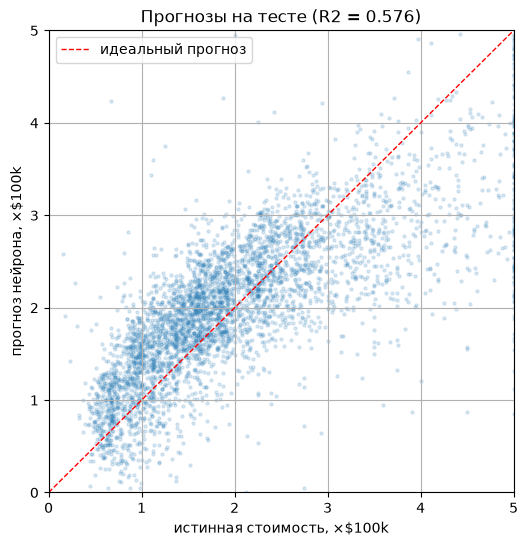

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, s=5, alpha=0.15)
lims = [0, 5]
plt.plot(lims, lims, 'r--', linewidth=1, label='идеальный прогноз')
plt.xlim(lims); plt.ylim(lims)
plt.xlabel('истинная стоимость, ×$100k')
plt.ylabel('прогноз нейрона, ×$100k')
plt.title('Прогнозы на тесте (R2 = %.3f)' % r2)
plt.legend()
plt.grid(True)
plt.show()

### Нейрон против аналитической линейной регрессии: веса

Если градиентный спуск сошёлся к оптимуму, веса нейрона должны совпасть с коэффициентами `LinearRegression` — тем самым подтверждается тезис из цели задания, что сеть из одного нейрона без активации *практически эквивалентна линейной регрессии*.


In [ ]:
weights_neuron = model[0].weight.data.cpu().numpy().ravel()
bias_neuron = model[0].bias.item()

weights_table = pd.DataFrame(
    {'вес нейрона (GD)': weights_neuron,
     'коэфф. LinearRegression': lr_sk.coef_.ravel()},
    index=data.feature_names)
print('смещение (bias): нейрон = %.4f | LinearRegression = %.4f' % (
    bias_neuron, lr_sk.intercept_[0]))
print('максимальное расхождение весов: %.2e' % np.abs(
    weights_neuron - lr_sk.coef_.ravel()).max())
weights_table.round(4)

смещение (bias): нейрон = -0.0000 | LinearRegression = -0.0000
максимальное расхождение весов: 3.04e-05


,вес нейрона (GD),коэфф. LinearRegression
MedInc,0.7390,0.7390
HouseAge,0.1060,0.1060
AveRooms,-0.2547,-0.2546
AveBedrms,0.2934,0.2934
Population,-0.0020,-0.0020
AveOccup,-0.0353,-0.0353
Latitude,-0.7757,-0.7758
Longitude,-0.7523,-0.7523


## 5. Выводы

1. **Пайплайн** выполнен по инструкции: данные загружены и стандартизованы, выборка разделена на train/test (80/20), модель собрана через `nn.Sequential(nn.Linear(8, 1))`, обучение — градиентным спуском (полный батч, MSE, SGD, lr = 0.1, 1000 эпох), качество измерено на тесте.
2. **Качество:** один нейрон даёт на тесте $R^2 \approx 0.58$ и RMSE $\approx 0.75$ сотен тысяч долларов (~75 тыс. \$ при медианной цене дома ~180 тыс. \$) — существенно лучше бейзлайна «предсказывать среднее» (RMSE $\approx 1.14$).
3. **Эквивалентность линейной регрессии подтверждена на практике:** обученные градиентным спуском веса совпали с аналитическим решением МНК (`sklearn.LinearRegression`) с точностью до $10^{-4}$–$10^{-5}$, и метрики обеих моделей идентичны. Нейрон без нелинейной активации — это и есть линейная регрессия.
4. **Практический урок про градиентный спуск:** результат сильно зависит от масштаба признаков и шага обучения. Без стандартизации признаки с масштабом тысяч (Population) доминировали бы в градиентах; слишком большой lr (0.5) на этих данных расходится, lr = 0.1 сходится к оптимуму за ~1000 полнобатчевых шагов (~1–2 секунды на CPU).
5. **Ограничение модели:** линейная зависимость не может захватить нелинейные эффекты (например, зависимость цены от географии: широта/долгота входят только линейно) — потолок качества одного нейрона на этих данных невысок, и его превышают модели с нелинейностями и учётом взаимодействий признаков.
